In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 설정 (윈도우: 맑은 고딕)
plt.rc("font", family="Malgun Gothic")
plt.rc("axes", unicode_minus=False)   # 마이너스 기호 깨짐 방지

df = pd.read_csv("webtoon_clean.csv")
print(df.shape)
print(df["is_munchkin"].sum(), "개 먼치킨")

(3846, 27)
282 개 먼치킨


In [2]:
# 연도별 전체 작품 수 vs 먼치킨 작품 수
yearly = df.groupby("year").agg(
    total=("titleId", "count"),
    munchkin=("is_munchkin", "sum")
)
yearly["ratio"] = yearly["munchkin"] / yearly["total"] * 100   # 비중(%)

print(yearly)

      total  munchkin      ratio
year                            
2005      2         0   0.000000
2006      7         0   0.000000
2007     18         1   5.555556
2008     37         0   0.000000
2009     46         1   2.173913
2010     60         1   1.666667
2011     67         1   1.492537
2012     65         1   1.538462
2013     80         4   5.000000
2014     81         2   2.469136
2015     89         2   2.247191
2016     83         3   3.614458
2017     79         2   2.531646
2018    121         1   0.826446
2019    187         7   3.743316
2020    254        17   6.692913
2021    383        18   4.699739
2022    438        30   6.849315
2023    420        46  10.952381
2024    490        68  13.877551
2025    529        48   9.073724
2026    310        29   9.354839


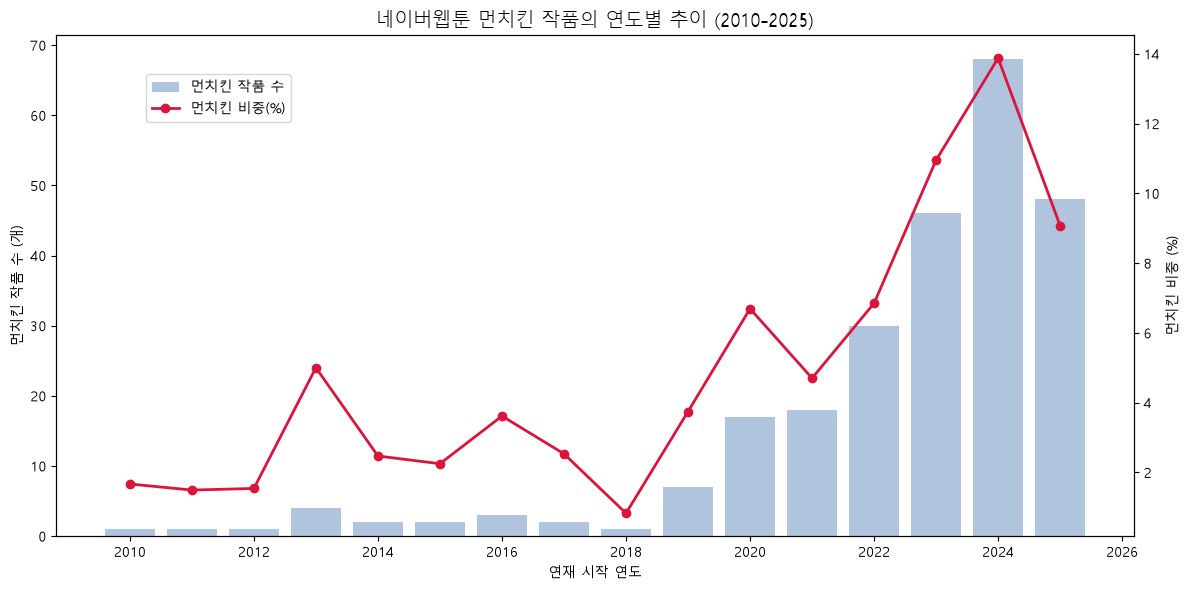

In [3]:
# 2026년은 부분 연도라 제외, 초기 연도는 작품 수가 적어 2010년부터
plot_data = yearly.loc[2010:2025]

fig, ax1 = plt.subplots(figsize=(12, 6))

# 막대: 연도별 먼치킨 작품 수
ax1.bar(plot_data.index, plot_data["munchkin"], color="lightsteelblue", label="먼치킨 작품 수")
ax1.set_xlabel("연재 시작 연도")
ax1.set_ylabel("먼치킨 작품 수 (개)")

# 선: 먼치킨 비중(%) — 오른쪽 축
ax2 = ax1.twinx()
ax2.plot(plot_data.index, plot_data["ratio"], color="crimson", marker="o", linewidth=2, label="먼치킨 비중(%)")
ax2.set_ylabel("먼치킨 비중 (%)")

plt.title("네이버웹툰 먼치킨 작품의 연도별 추이 (2010-2025)", fontsize=14)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.savefig("munchkin_trend.png", dpi=150)   # 그래프를 이미지 파일로도 저장
plt.show()

In [4]:
from collections import Counter

# 먼치킨 작품들의 태그를 전부 모아서 빈도 세기
munchkin_tags = df[df["is_munchkin"]]["tags"].str.split(", ")

tag_counter = Counter()
for tag_list in munchkin_tags:
    tag_counter.update(tag_list)

# 상위 20개 (자기 자신인 '먼치킨' 제외하고 보기)
for tag, cnt in tag_counter.most_common(21):
    if tag != "먼치킨":
        print(f"{tag}: {cnt}개 ({cnt/282*100:.0f}%)")

판타지: 163개 (58%)
액션: 141개 (50%)
소설원작: 127개 (45%)
사이다: 67개 (24%)
무협/사극: 62개 (22%)
성장물: 59개 (21%)
인외존재: 58개 (21%)
고인물: 55개 (20%)
액션판타지: 54개 (19%)
복수극: 48개 (17%)
완결판타지: 48개 (17%)
크리처: 47개 (17%)
헌터물: 47개 (17%)
회귀: 46개 (16%)
게임판타지: 46개 (16%)
상태창: 39개 (14%)
현대: 37개 (13%)
이능력배틀물: 33개 (12%)
모험: 31개 (11%)
이능력: 31개 (11%)


In [5]:
# novelOriginAuthors가 비어있지 않으면(=[]가 아니면) 웹소설 원작
df["is_novel"] = df["novelOriginAuthors"].astype(str) != "[]"

# 먼치킨 vs 비먼치킨의 웹소설 원작 비율 비교
comparison = df.groupby("is_munchkin")["is_novel"].mean() * 100
print(comparison)

is_munchkin
False    17.789001
True     45.035461
Name: is_novel, dtype: float64


In [6]:
# 먼치킨 vs 비먼치킨: 별점과 관심수 비교
print(df.groupby("is_munchkin")[["starScore", "favoriteCount"]].mean())
print()
# 관심수는 극단값 영향이 크니 중앙값도 함께
print(df.groupby("is_munchkin")[["starScore", "favoriteCount"]].median())

             starScore  favoriteCount
is_munchkin                          
False         9.717517   94686.647868
True          9.677510  201510.929078

             starScore  favoriteCount
is_munchkin                          
False          9.89216        52841.5
True           9.83926       110891.0


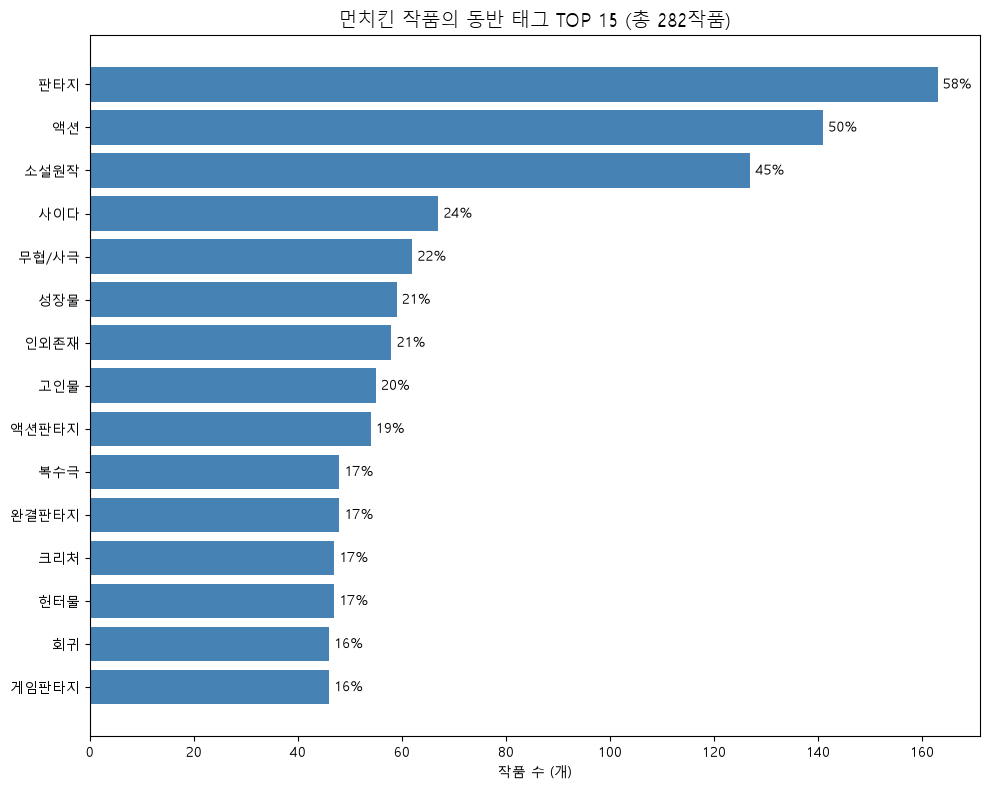

In [7]:
# 어제 만든 tag_counter에서 상위 15개 (먼치킨 자신 제외)
top_tags = [(tag, cnt) for tag, cnt in tag_counter.most_common(16) if tag != "먼치킨"][:15]
tags_names = [t[0] for t in top_tags][::-1]   # [::-1] = 뒤집기 (가로 막대는 아래→위로 그려져서)
tags_counts = [t[1] for t in top_tags][::-1]

plt.figure(figsize=(10, 8))
plt.barh(tags_names, tags_counts, color="steelblue")
plt.xlabel("작품 수 (개)")
plt.title("먼치킨 작품의 동반 태그 TOP 15 (총 282작품)", fontsize=14)

# 막대 끝에 비율(%) 표시
for i, cnt in enumerate(tags_counts):
    plt.text(cnt + 1, i, f"{cnt/282*100:.0f}%", va="center")

plt.tight_layout()
plt.savefig("munchkin_tags.png", dpi=150)
plt.show()

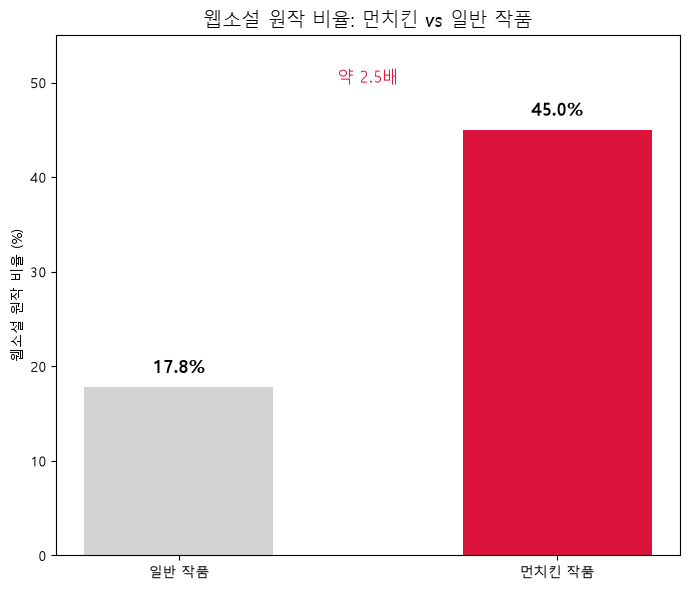

In [8]:
labels = ["일반 작품", "먼치킨 작품"]
values = [17.8, 45.0]
colors = ["lightgray", "crimson"]

plt.figure(figsize=(7, 6))
bars = plt.bar(labels, values, color=colors, width=0.5)
plt.ylabel("웹소설 원작 비율 (%)")
plt.title("웹소설 원작 비율: 먼치킨 vs 일반 작품", fontsize=14)
plt.ylim(0, 55)

# 막대 위에 값 표시
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 1.5, f"{v:.1f}%",
             ha="center", fontsize=13, fontweight="bold")

# 배율 주석
plt.text(0.5, 50, "약 2.5배", ha="center", fontsize=12, color="crimson")

plt.tight_layout()
plt.savefig("munchkin_novel.png", dpi=150)
plt.show()

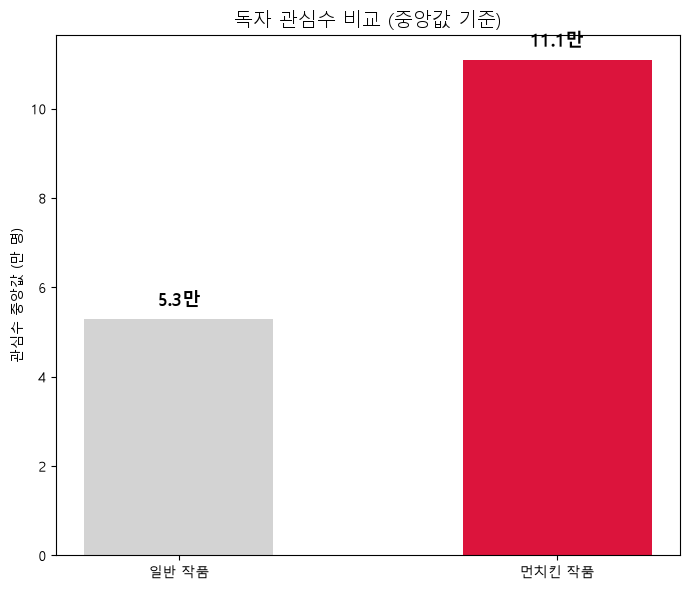

In [11]:
med = df.groupby("is_munchkin")["favoriteCount"].median() / 10000  # 만 단위

plt.figure(figsize=(7, 6))
bars = plt.bar(["일반 작품", "먼치킨 작품"], [med[False], med[True]],
               color=["lightgray", "crimson"], width=0.5)
plt.ylabel("관심수 중앙값 (만 명)")
plt.title("독자 관심수 비교 (중앙값 기준)", fontsize=14)

for bar, v in zip(bars, [med[False], med[True]]):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.3, f"{v:.1f}만",
             ha="center", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("munchkin_favorite.png", dpi=150)
plt.show()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", family="Malgun Gothic")
plt.rc("axes", unicode_minus=False)

df = pd.read_csv("webtoon_clean.csv")
df["is_novel"] = df["novelOriginAuthors"].astype(str) != "[]"   # 파생 변수 다시 생성
print(df.shape)

(3846, 28)


In [3]:
mun = df[df["is_munchkin"]]
novel_trend = mun.groupby("year").agg(
    munchkin_total=("titleId", "count"),
    novel_count=("is_novel", "sum")
)
novel_trend["novel_ratio"] = novel_trend["novel_count"] / novel_trend["munchkin_total"] * 100
print(novel_trend.loc[2015:2025])

      munchkin_total  novel_count  novel_ratio
year                                          
2015               2            0     0.000000
2016               3            0     0.000000
2017               2            0     0.000000
2018               1            0     0.000000
2019               7            1    14.285714
2020              17            9    52.941176
2021              18            9    50.000000
2022              30           18    60.000000
2023              46           24    52.173913
2024              68           34    50.000000
2025              48           19    39.583333


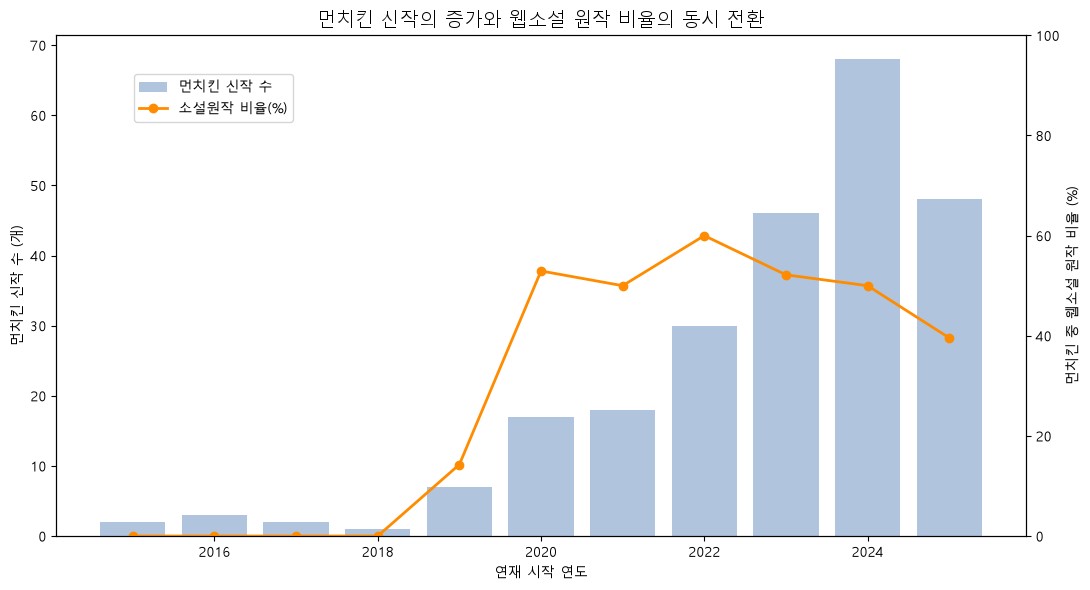

In [4]:
plot = novel_trend.loc[2015:2025]

fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.bar(plot.index, plot["munchkin_total"], color="lightsteelblue", label="먼치킨 신작 수")
ax1.set_xlabel("연재 시작 연도")
ax1.set_ylabel("먼치킨 신작 수 (개)")

ax2 = ax1.twinx()
ax2.plot(plot.index, plot["novel_ratio"], color="darkorange", marker="o", linewidth=2, label="소설원작 비율(%)")
ax2.set_ylabel("먼치킨 중 웹소설 원작 비율 (%)")
ax2.set_ylim(0, 100)

plt.title("먼치킨 신작의 증가와 웹소설 원작 비율의 동시 전환", fontsize=14)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.savefig("munchkin_novel_trend.png", dpi=150)
plt.show()